# 02. Исследовательский анализ данных

**Цель:** найти закономерности, связанные с оттоком, и проверить четыре бизнес-гипотезы:

1. У клиентов с помесячным договором доля оттока выше, чем у клиентов с долгосрочным договором.
2. У клиентов с небольшим стажем доля оттока выше.
3. У клиентов без технической поддержки доля оттока выше.
4. Способ оплаты связан с различиями в доле оттока.

Анализ описательный: он показывает связь признаков с оттоком, но не доказывает причинно-следственные отношения.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)  # у клиентов с tenure=0 платежей ещё не было
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


## 1. Стаж клиентов

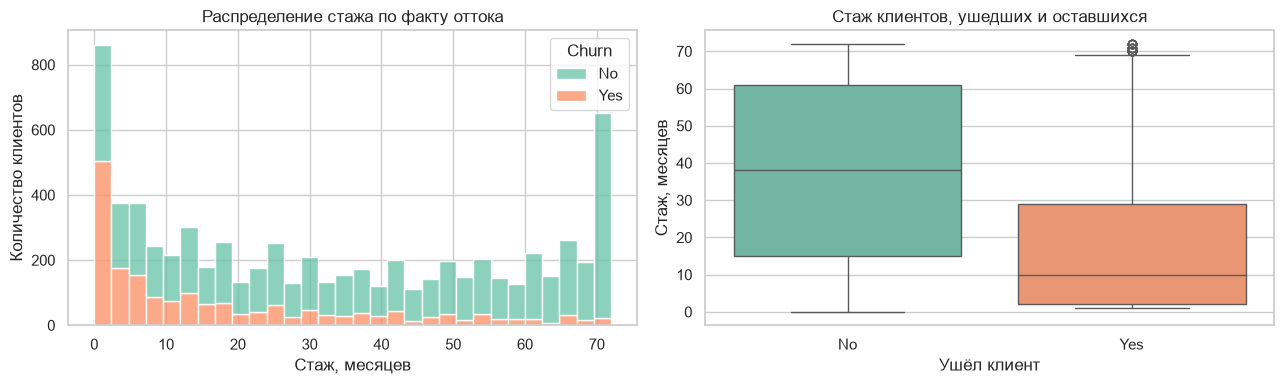

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack",
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Распределение стажа по факту оттока")
axes[0].set_xlabel("Стаж, месяцев")
axes[0].set_ylabel("Количество клиентов")

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Стаж клиентов, ушедших и оставшихся")
axes[1].set_xlabel("Ушёл клиент")
axes[1].set_ylabel("Стаж, месяцев")

plt.tight_layout()
plt.show()

In [3]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
)

tenure_stats = (
    df.groupby("tenure_group", observed=True)["ChurnFlag"]
    .agg(customers="count", churn_rate="mean")
    .assign(churn_rate_pct=lambda x: (x["churn_rate"] * 100).round(2))
    .drop(columns="churn_rate")
)
tenure_stats

,customers,churn_rate_pct
tenure_group,,
0-12,2186,47.44
13-24,1024,28.71
25-48,1594,20.39
49-72,2239,9.51


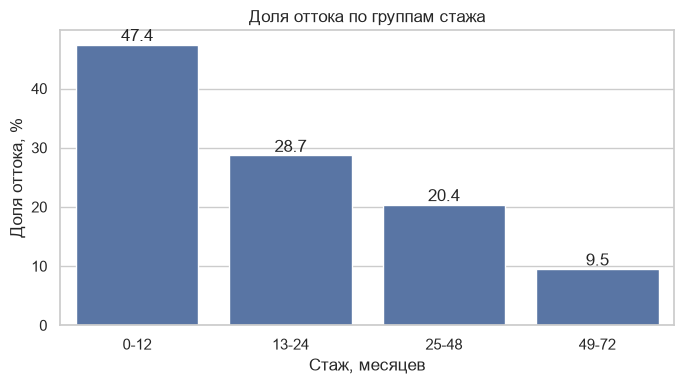

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=tenure_stats.reset_index(),
    x="tenure_group",
    y="churn_rate_pct",
    color="#4C72B0",
    ax=ax,
)

ax.set_title("Доля оттока по группам стажа")
ax.set_xlabel("Стаж, месяцев")
ax.set_ylabel("Доля оттока, %")
ax.bar_label(ax.containers[0], fmt="%.1f")

plt.tight_layout()
plt.show()

## 2. Тип договора

In [5]:
contract_stats = (
    df.groupby("Contract")["ChurnFlag"]
    .agg(customers="count", churn_rate="mean")
    .assign(churn_rate_pct=lambda x: (x["churn_rate"] * 100).round(2))
    .drop(columns="churn_rate")
    .sort_values("churn_rate_pct", ascending=False)
)
contract_stats

,customers,churn_rate_pct
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


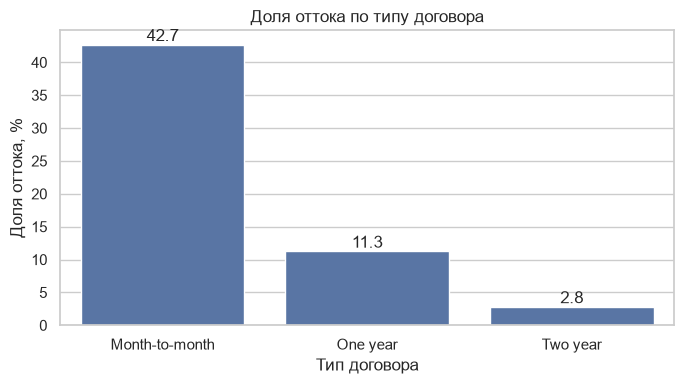

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=contract_stats.reset_index(),
    x="Contract",
    y="churn_rate_pct",
    color="#4C72B0",
    ax=ax,
)

ax.set_title("Доля оттока по типу договора")
ax.set_xlabel("Тип договора")
ax.set_ylabel("Доля оттока, %")
ax.bar_label(ax.containers[0], fmt="%.1f")

plt.tight_layout()
plt.show()

## 3. Способ оплаты

In [7]:
payment_stats = (
    df.groupby("PaymentMethod")["ChurnFlag"]
    .agg(customers="count", churn_rate="mean")
    .assign(churn_rate_pct=lambda x: (x["churn_rate"] * 100).round(2))
    .drop(columns="churn_rate")
    .sort_values("churn_rate_pct", ascending=False)
)
payment_stats

,customers,churn_rate_pct
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24


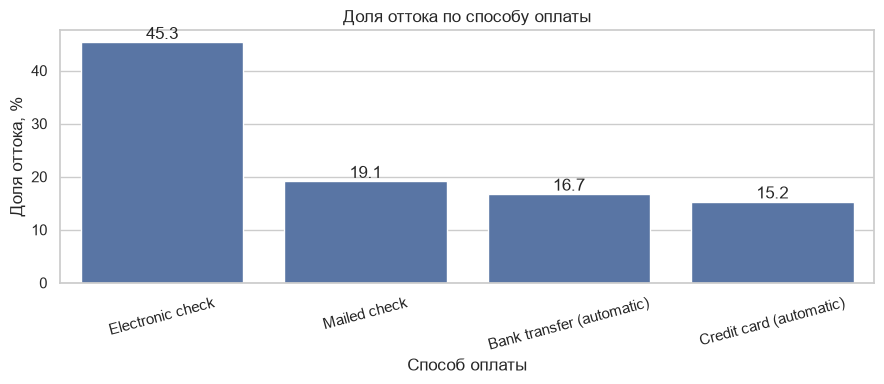

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(
    data=payment_stats.reset_index(),
    x="PaymentMethod",
    y="churn_rate_pct",
    color="#4C72B0",
    ax=ax,
)

ax.set_title("Доля оттока по способу оплаты")
ax.set_xlabel("Способ оплаты")
ax.set_ylabel("Доля оттока, %")
ax.tick_params(axis="x", rotation=15)
ax.bar_label(ax.containers[0], fmt="%.1f")

plt.tight_layout()
plt.show()

## 4. Интернет и техническая поддержка

In [9]:
internet_stats = (
    df.groupby("InternetService")["ChurnFlag"]
    .agg(customers="count", churn_rate="mean")
    .assign(churn_rate_pct=lambda x: (x["churn_rate"] * 100).round(2))
    .drop(columns="churn_rate")
    .sort_values("churn_rate_pct", ascending=False)
)
internet_stats

,customers,churn_rate_pct
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No,1526,7.40


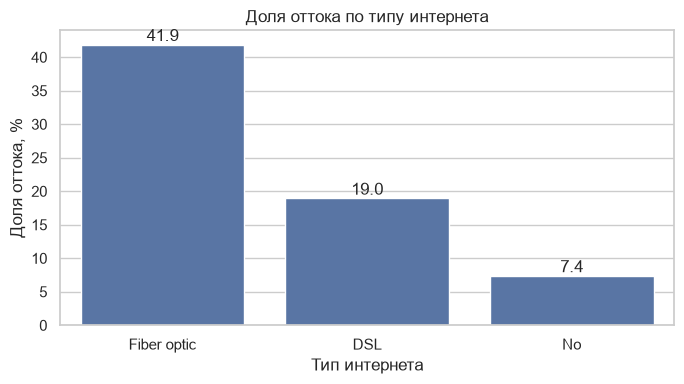

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=internet_stats.reset_index(),
    x="InternetService",
    y="churn_rate_pct",
    color="#4C72B0",
    ax=ax,
)

ax.set_title("Доля оттока по типу интернета")
ax.set_xlabel("Тип интернета")
ax.set_ylabel("Доля оттока, %")
ax.bar_label(ax.containers[0], fmt="%.1f")

plt.tight_layout()
plt.show()

In [11]:
internet_users = df[df["InternetService"] != "No"]

tech_support_stats = (
    internet_users.groupby("TechSupport")["ChurnFlag"]
    .agg(customers="count", churn_rate="mean")
    .assign(churn_rate_pct=lambda x: (x["churn_rate"] * 100).round(2))
    .drop(columns="churn_rate")
    .sort_values("churn_rate_pct", ascending=False)
)
tech_support_stats

,customers,churn_rate_pct
TechSupport,,
No,3473,41.64
Yes,2044,15.17


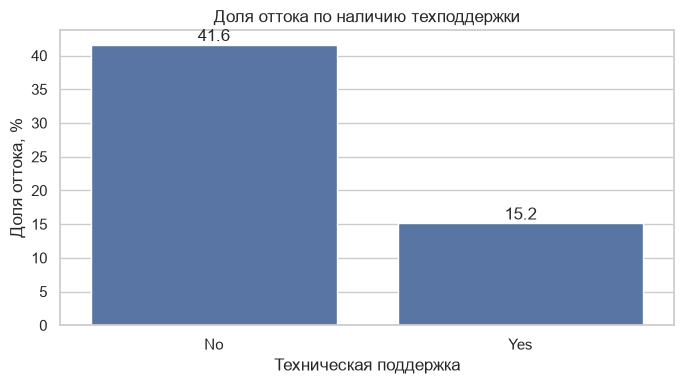

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=tech_support_stats.reset_index(),
    x="TechSupport",
    y="churn_rate_pct",
    color="#4C72B0",
    ax=ax,
)

ax.set_title("Доля оттока по наличию техподдержки")
ax.set_xlabel("Техническая поддержка")
ax.set_ylabel("Доля оттока, %")
ax.bar_label(ax.containers[0], fmt="%.1f")

plt.tight_layout()
plt.show()

## 5. Платежи

In [13]:
payment_summary = (
    df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]]
    .agg(["mean", "median"])
    .round(2)
)
payment_summary

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

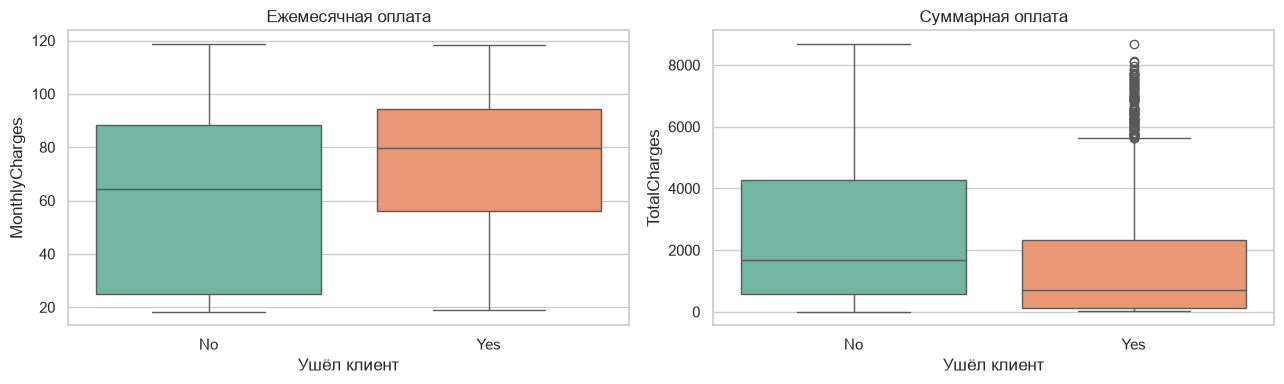

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Ежемесячная оплата")
axes[0].set_xlabel("Ушёл клиент")
axes[0].set_ylabel("MonthlyCharges")

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges",
    hue="Churn",
    palette="Set2",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Суммарная оплата")
axes[1].set_xlabel("Ушёл клиент")
axes[1].set_ylabel("TotalCharges")

plt.tight_layout()
plt.show()

## 6. Корреляция числовых признаков

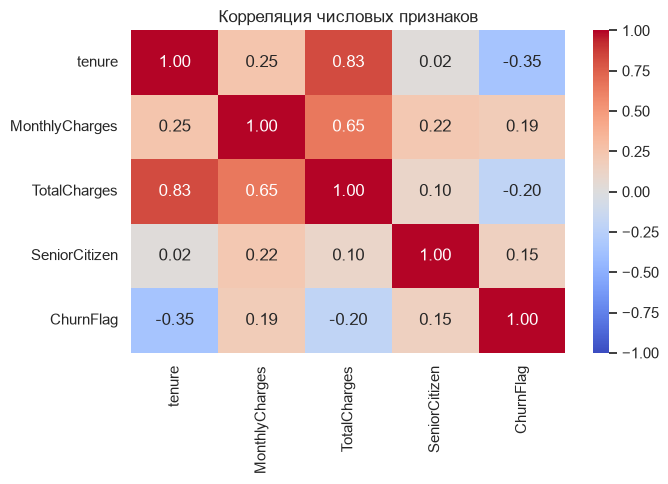

In [15]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]
correlation = df[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Корреляция числовых признаков")

plt.tight_layout()
plt.show()

## 7. Проверка бизнес-гипотез

In [16]:
def compare_churn_rate(data, group_mask, hypothesis):
    group = data[group_mask]
    rest = data[~group_mask]

    return {
        "Гипотеза": hypothesis,
        "В группе, чел.": len(group),
        "Отток в группе, %": round(group["ChurnFlag"].mean() * 100, 2),
        "Вне группы, чел.": len(rest),
        "Отток вне группы, %": round(rest["ChurnFlag"].mean() * 100, 2),
    }


hypotheses_table = pd.DataFrame(
    [
        compare_churn_rate(
            df,
            df["Contract"].eq("Month-to-month"),
            "H1. Помесячный договор",
        ),
        compare_churn_rate(
            df,
            df["tenure"].le(12),
            "H2. Стаж до 12 месяцев",
        ),
        compare_churn_rate(
            internet_users,
            internet_users["TechSupport"].eq("No"),
            "H3. Нет техподдержки (клиенты с интернетом)",
        ),
        compare_churn_rate(
            df,
            df["PaymentMethod"].eq("Electronic check"),
            "H4. Electronic check",
        ),
    ]
)

hypotheses_table["Разница, п.п."] = (
    hypotheses_table["Отток в группе, %"] - hypotheses_table["Отток вне группы, %"]
).round(2)

hypotheses_table

,Гипотеза,"В группе, чел.","Отток в группе, %","Вне группы, чел.","Отток вне группы, %","Разница, п.п."
0,H1. Помесячный договор,3875,42.71,3168,6.76,35.95
1,H2. Стаж до 12 месяцев,2186,47.44,4857,17.13,30.31
2,H3. Нет техподдержки (клиенты с интернетом),3473,41.64,2044,15.17,26.47
3,H4. Electronic check,2365,45.29,4678,17.06,28.23


## 8. Выводы EDA

**H1. Тип договора.** Данные согласуются с гипотезой: доля оттока при помесячном договоре — **42,7%**, при годовом — **11,3%**, при двухлетнем — **2,8%**.

**H2. Стаж.** Данные согласуются с гипотезой: у клиентов со стажем до 12 месяцев отток — **47,4%**, у клиентов со стажем больше 12 месяцев — **17,1%**. Средний стаж ушедших — **18,0 месяца**, оставшихся — **37,6 месяца**.

**H3. Техподдержка.** Среди клиентов с интернетом доля оттока без техподдержки — **41,6%**, с поддержкой — **15,2%**. Данные согласуются с гипотезой.

**H4. Способ оплаты.** Данные согласуются с гипотезой: у клиентов с `Electronic check` отток — **45,3%**, у остальных способов — от **15,2%** до **19,1%**.

**Платежи.** Ушедшие клиенты в среднем платят за услуги больше: **74,44** против **61,27** в месяц. Это может быть связано с тем, что дорогие тарифы чаще выбирают клиенты на помесячном договоре.

**Корреляции.** Наиболее заметна отрицательная связь оттока со стажем (`-0,35`) и положительная — с ежемесячной оплатой (`0,19`). Корреляция показывает связь, но не доказывает причинность.

**Ограничения.** Это описательный анализ демонстрационного среза данных. Он не учитывает совместное влияние признаков; для этого на следующем этапе будут обучены модели машинного обучения.